# Exercise 2: Flight delays

In [1]:
import pandas as pd

flights = pd.read_csv("data/flights.csv.zip")
airlines = pd.read_csv("data/airlines.csv")

## 1. Build the analysis sample

### 1(a) Rows, dimensions, data type, and exact duplicates

Each row in `flights` represents one scheduled flight record on a particular date. The same flight number can appear on different dates, so repeated flight numbers alone do not make duplicate records. Each row in `airlines` represents one carrier code and its airline name.

The duplicate check below compares every original column in each file. An exact duplicate is a candidate for removal because it repeats the same recorded observation; it should only be removed after confirming it is an accidental duplicate. The source records are retained here.

In [2]:
# Show the dimensions of both data frames.
shapes = pd.DataFrame(
    {"rows": [flights.shape[0], airlines.shape[0]],
     "columns": [flights.shape[1], airlines.shape[1]]},
    index=["flights", "airlines"]
)
print(shapes)

print("arr_delay data type:", flights["arr_delay"].dtype)
print("Exact duplicate flight rows:", flights.duplicated().sum())
print("Exact duplicate airline rows:", airlines.duplicated().sum())

            rows  columns
flights   336776       19
airlines      16        2
arr_delay data type: float64
Exact duplicate flight rows: 0
Exact duplicate airline rows: 0


The flight data contain one observation per flight record, but an airline flight number can recur on different dates. The dimensions above report the number of rows and columns in each file. `arr_delay` is numeric (minutes), with missing values represented as nulls. Exact duplicates are assessed across all columns, rather than by flight number alone. If exact duplicates were found, they would be investigated before removal, but duplicate flight numbers on different dates should remain. However, there's no need for that.

### 1(b) Known and missing arrival delays; late-arrival indicator

A known arrival delay is a non-missing value in `arr_delay`; a missing value means the arrival delay is unavailable. The two counts should sum to the number of flight records. A late arrival is defined as an arrival delay of **15 minutes or more**. Negative delays (early arrivals) and delays below 15 minutes are not late. Missing delays remain missing in the indicator.

In [3]:
known_arrival_delay = flights["arr_delay"].notna().sum()
missing_arrival_delay = flights["arr_delay"].isna().sum()

print("Flights with a known arrival delay:", known_arrival_delay)
print("Flights with a missing arrival delay:", missing_arrival_delay)
print("Total flights:", len(flights))
print("Counts add up to total:", known_arrival_delay + missing_arrival_delay == len(flights))

flights["late_arrival"] = flights["arr_delay"].ge(15).where(flights["arr_delay"].notna(), pd.NA).astype("boolean")
print("\nLate-arrival indicator counts (including missing):")
print(flights["late_arrival"].value_counts(dropna=False).rename(index={True: "Late (True)", False: "Not late (False)"}))

Flights with a known arrival delay: 327346
Flights with a missing arrival delay: 9430
Total flights: 336776
Counts add up to total: True

Late-arrival indicator counts (including missing):
late_arrival
Not late (False)    247246
Late (True)          80100
<NA>                  9430
Name: count, dtype: Int64


The indicator uses `>= 15`, so a delay of exactly 15 minutes is late. An early arrival and a 14-minute delay are not late. Because the indicator uses pandas' nullable Boolean type, a missing `arr_delay` produces `<NA>` and is not silently counted as on time.

In [4]:
examples = pd.DataFrame({"arr_delay": [-5, 14, 15, pd.NA]})
examples["late_arrival"] = examples["arr_delay"].ge(15).where(examples["arr_delay"].notna(), pd.NA).astype("boolean")
print(examples.to_string(index=False))

arr_delay  late_arrival
       -5         False
       14         False
       15          True
     <NA>          <NA>


## 2. Attach airline names

The `airlines` lookup should contain one row per `carrier` code. The merge below checks that key is unique, uses pandas' `many_to_one` validation, and keeps every flight record. The merge indicator is used to identify any carrier codes without a lookup match.

In [5]:
duplicate_lookup_codes = airlines.loc[airlines["carrier"].duplicated(keep=False), "carrier"].unique()
print("Airline lookup rows:", len(airlines))
print("Unique carrier codes:", airlines["carrier"].nunique())
print("Duplicate lookup codes:", sorted(duplicate_lookup_codes.tolist()))

rows_before_join = len(flights)
flights_named = flights.merge(
    airlines,
    on="carrier",
    how="left",
    validate="many_to_one",
    indicator=True
)
rows_after_join = len(flights_named)
unmatched_codes = sorted(
    flights_named.loc[flights_named["_merge"] == "left_only", "carrier"].dropna().unique().tolist()
)
matched_flights = int((flights_named["_merge"] == "both").sum())

print("\nFlight rows before join:", rows_before_join)
print("Flight rows after join:", rows_after_join)
print("Matched flight rows:", matched_flights)
print("Unmatched carrier codes:", unmatched_codes)
print("All flight rows matched:", rows_after_join == rows_before_join and not unmatched_codes)

Airline lookup rows: 16
Unique carrier codes: 16
Duplicate lookup codes: []

Flight rows before join: 336776
Flight rows after join: 336776
Matched flight rows: 336776
Unmatched carrier codes: []
All flight rows matched: True


The lookup has 16 rows and 16 unique carrier codes, with no duplicate keys. All 336,776 flight records match a lookup entry, so there are no unmatched carrier codes. The row count is unchanged after the validated many-to-one join, so each flight remains represented once. `flights_named` now includes the readable airline `name` and is the data frame to use for the airline table in Exercise 3.

## 3. Give the editor a checkable table

### 3(a) The five busiest airlines and an all-airlines row

Rank airlines by the number of scheduled flight records. For each of the five busiest airlines, report its scheduled flights, flights with a known arrival delay, late arrivals, and the late-arrival percentage among flights with a known delay. Add a final row that combines **all** airlines, including those outside the top five. Percentages are rounded to one decimal place for display.

In [6]:
airline_summary = (
    flights_named.groupby(["carrier", "name"], as_index=False)
    .agg(
        scheduled_flights=("carrier", "size"),
        known_arrival_delays=("arr_delay", "count"),
        late_arrivals=("late_arrival", "sum"),
    )
    .sort_values("scheduled_flights", ascending=False)
    .reset_index(drop=True)
)
airline_summary["late_percentage"] = (
    airline_summary["late_arrivals"] / airline_summary["known_arrival_delays"] * 100
)

top_five = airline_summary.head(5).copy()
all_airlines_row = pd.DataFrame([{
    "carrier": "ALL",
    "name": "All airlines",
    "scheduled_flights": len(flights_named),
    "known_arrival_delays": flights_named["arr_delay"].count(),
    "late_arrivals": int(flights_named["late_arrival"].sum()),
}])
all_airlines_row["late_percentage"] = (
    all_airlines_row["late_arrivals"] / all_airlines_row["known_arrival_delays"] * 100
)

editor_table = pd.concat([top_five, all_airlines_row], ignore_index=True)
editor_table = editor_table[[
    "name", "scheduled_flights", "known_arrival_delays", "late_arrivals", "late_percentage"
]].rename(columns={
    "name": "Airline",
    "scheduled_flights": "Scheduled flights",
    "known_arrival_delays": "Flights with known arrival delay",
    "late_arrivals": "Late arrivals (15+ min)",
    "late_percentage": "Late among known delays (%)",
})
editor_table["Late among known delays (%)"] = editor_table["Late among known delays (%)"].round(1)
print(editor_table.to_string(index=False))

                 Airline  Scheduled flights  Flights with known arrival delay  Late arrivals (15+ min)  Late among known delays (%)
   United Air Lines Inc.              58665                             57782                    13004                         22.5
         JetBlue Airways              54635                             54049                    14567                         27.0
ExpressJet Airlines Inc.              54173                             51108                    16399                         32.1
    Delta Air Lines Inc.              48110                             47658                     9038                         19.0
  American Airlines Inc.              32729                             31947                     6203                         19.4
            All airlines             336776                            327346                    80100                         24.5


The ranking is based on scheduled flight records, not on the subset with a known arrival delay. The all-airlines row is recalculated from every joined flight record, rather than by adding only the five displayed airlines.

### 3(b) Recalculate one airline's percentage from flight records

Using the busiest airline from the ranking. Counting its late-arrival records and its records with a known `arr_delay` directly from the underlying flight rows, then verifying the percentage shown in the table.

In [7]:
selected_airline = top_five.iloc[0]["name"]
selected_records = flights_named.loc[flights_named["name"] == selected_airline]
selected_numerator = int(selected_records["arr_delay"].ge(15).sum())
selected_denominator = int(selected_records["arr_delay"].notna().sum())
selected_percentage = selected_numerator / selected_denominator * 100
summary_percentage = float(top_five.iloc[0]["late_percentage"])

print("Airline:", selected_airline)
print("Late-arrival percentage arithmetic:")
print(f"{selected_numerator} / {selected_denominator} × 100 = {selected_percentage:.1f}%")
print(f"Percentage in the table: {summary_percentage:.1f}%")
print("Agrees after rounding:", round(selected_percentage, 1) == round(summary_percentage, 1))

Airline: United Air Lines Inc.
Late-arrival percentage arithmetic:
13004 / 57782 × 100 = 22.5%
Percentage in the table: 22.5%
Agrees after rounding: True


### 3(c) Alternative denominator for the all-airlines row

The alternative rate divides known late arrivals by **all scheduled flights**, including records with a missing arrival delay. Comparing it with the headline percentage, whose denominator includes only flights with a known arrival delay. Reporting the difference in percentage points.

In [8]:
all_scheduled = int(all_airlines_row.iloc[0]["scheduled_flights"])
all_known_delays = int(all_airlines_row.iloc[0]["known_arrival_delays"])
all_late_arrivals = int(all_airlines_row.iloc[0]["late_arrivals"])
headline_rate = all_late_arrivals / all_known_delays * 100
alternative_rate = all_late_arrivals / all_scheduled * 100
difference_pp = alternative_rate - headline_rate

print(f"Headline rate: {all_late_arrivals} / {all_known_delays} × 100 = {headline_rate:.1f}%")
print(f"Alternative rate: {all_late_arrivals} / {all_scheduled} × 100 = {alternative_rate:.1f}%")
print(f"Change: {difference_pp:.1f} percentage points")
print("The alternative denominator includes", all_scheduled - all_known_delays,
      "flights whose arrival delay is missing. It therefore treats those records as not late in this rate, lowering the percentage.")

Headline rate: 80100 / 327346 × 100 = 24.5%
Alternative rate: 80100 / 336776 × 100 = 23.8%
Change: -0.7 percentage points
The alternative denominator includes 9430 flights whose arrival delay is missing. It therefore treats those records as not late in this rate, lowering the percentage.


## 4. Pitch and illustrate an original finding

### 4(a) The pitch

**Reader:** A travel editor advising readers who can choose when to depart from a New York City airport.

**Question:** How does the share of flights arriving at least 15 minutes late differ between morning and evening departures at EWR, JFK, and LGA?

**Measure and scope:** Late arrivals are flights with `arr_delay >= 15` minutes. The denominator is flights with a known `arr_delay`. Morning means scheduled departure hours 06-11 (06:00-11:59); evening means hours 18-23 (18:00-23:59). Including 2013 flights from EWR, JFK, and LGA in those two time windows only. Reporting the number of flights behind each airport-period estimate and the total number represented in the figure.

In [9]:
from plotnine import (
    aes, element_text, facet_wrap, geom_col, geom_line, geom_point, geom_text,
    ggplot, labs, scale_x_discrete, scale_y_continuous, theme, theme_minimal
)

figure_records = flights_named.loc[
    flights_named["hour"].between(6, 11) | flights_named["hour"].between(18, 23)
].copy()
figure_records = figure_records.loc[figure_records["arr_delay"].notna()].copy()
figure_records["departure_period"] = "Evening (18-23)"
figure_records.loc[
    figure_records["hour"].between(6, 11), "departure_period"
] = "Morning (06-11)"
figure_records["late_arrival_for_figure"] = figure_records["arr_delay"].ge(15)

figure_data = (
    figure_records.groupby(["origin", "departure_period"], as_index=False, observed=True)
    .agg(
        flights=("arr_delay", "size"),
        late_arrivals=("late_arrival_for_figure", "sum"),
    )
)
figure_data["late_percentage"] = 100 * figure_data["late_arrivals"] / figure_data["flights"]
figure_data["rate_label"] = figure_data["late_percentage"].map(lambda value: f"{value:.1f}%")
figure_data["departure_period"] = pd.Categorical(
    figure_data["departure_period"],
    categories=["Morning (06-11)", "Evening (18-23)"],
    ordered=True,
)
figure_data = figure_data.sort_values(["origin", "departure_period"])

print("Flights represented in the figure:", len(figure_records))
print("\nFlights and late-arrival rates by airport and departure period:")
print(figure_data[["origin", "departure_period", "flights", "late_arrivals", "late_percentage"]].to_string(
    index=False,
    formatters={"late_percentage": lambda value: f"{value:.1f}%"},
))

Flights represented in the figure: 198389

Flights and late-arrival rates by airport and departure period:
origin departure_period  flights  late_arrivals late_percentage
   EWR  Morning (06-11)    45944           7315           15.9%
   EWR  Evening (18-23)    23618           9342           39.6%
   JFK  Morning (06-11)    37728           5726           15.2%
   JFK  Evening (18-23)    28868           9378           32.5%
   LGA  Morning (06-11)    42974           6394           14.9%
   LGA  Evening (18-23)    19257           6300           32.7%


### 4(b) First figure version

The first version uses bars. Both versions use the same records, airport panels, period order, labels, and 0-50% vertical scale so the visual edit can be compared directly.

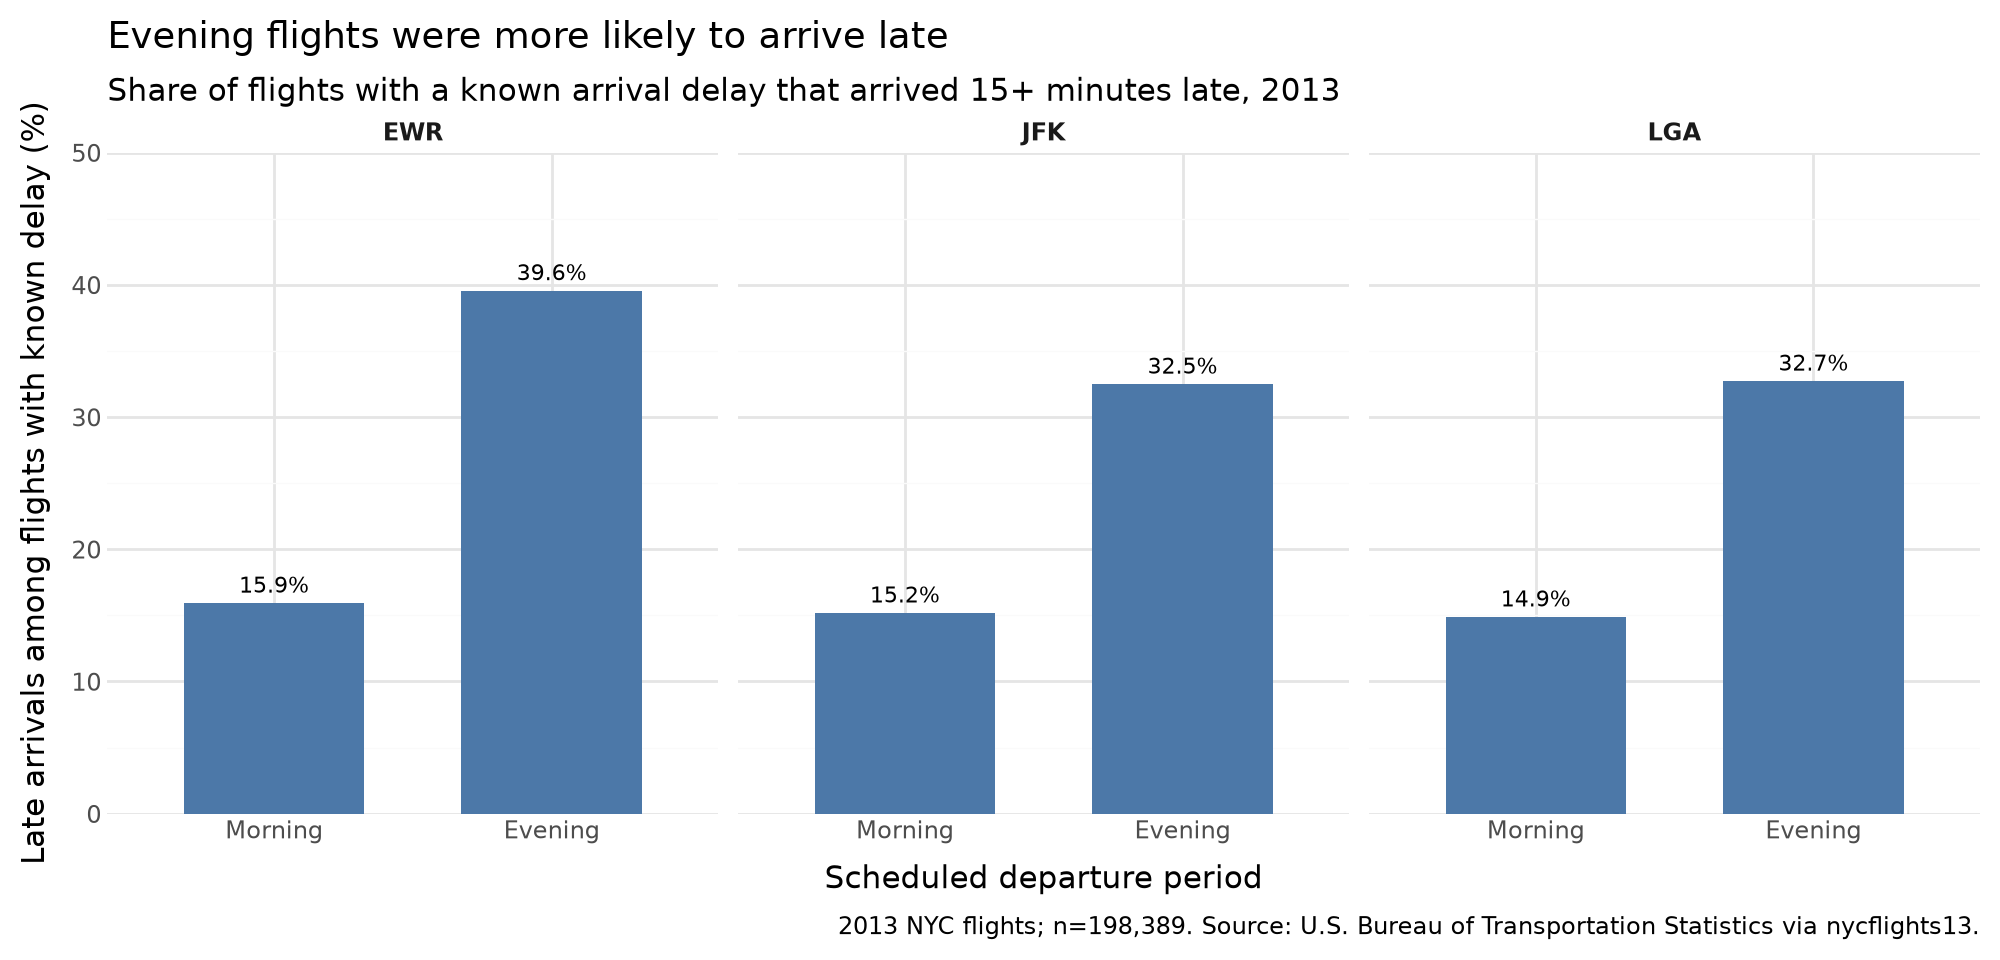

In [10]:
plot_theme = theme_minimal(base_size=11) + theme(
    figure_size=(10, 4.8),
    legend_position="none",
    strip_text=element_text(weight="bold"),
)
plot_labels = labs(
    title="Evening flights were more likely to arrive late",
    subtitle="Share of flights with a known arrival delay that arrived 15+ minutes late, 2013",
    x="Scheduled departure period",
    y="Late arrivals among flights with known delay (%)",
    caption=f"2013 NYC flights; n={len(figure_records):,}. Source: U.S. Bureau of Transportation Statistics via nycflights13.",
)

first_version = (
    ggplot(figure_data, aes(x="departure_period", y="late_percentage"))
    + geom_col(fill="#4C78A8", width=0.65)
    + geom_text(aes(label="rate_label"), nudge_y=1.4, size=8)
    + facet_wrap("~origin", nrow=1)
    + scale_x_discrete(labels={"Morning (06-11)": "Morning", "Evening (18-23)": "Evening"})
    + scale_y_continuous(limits=(0, 50), breaks=[0, 10, 20, 30, 40, 50], expand=(0, 0))
    + plot_labels
    + plot_theme
)
first_version

### 4(c) Edited figure and design decision

The final version changes the geometry from bars to connected points, while keeping the data, labels, panels, and axis limits the same.

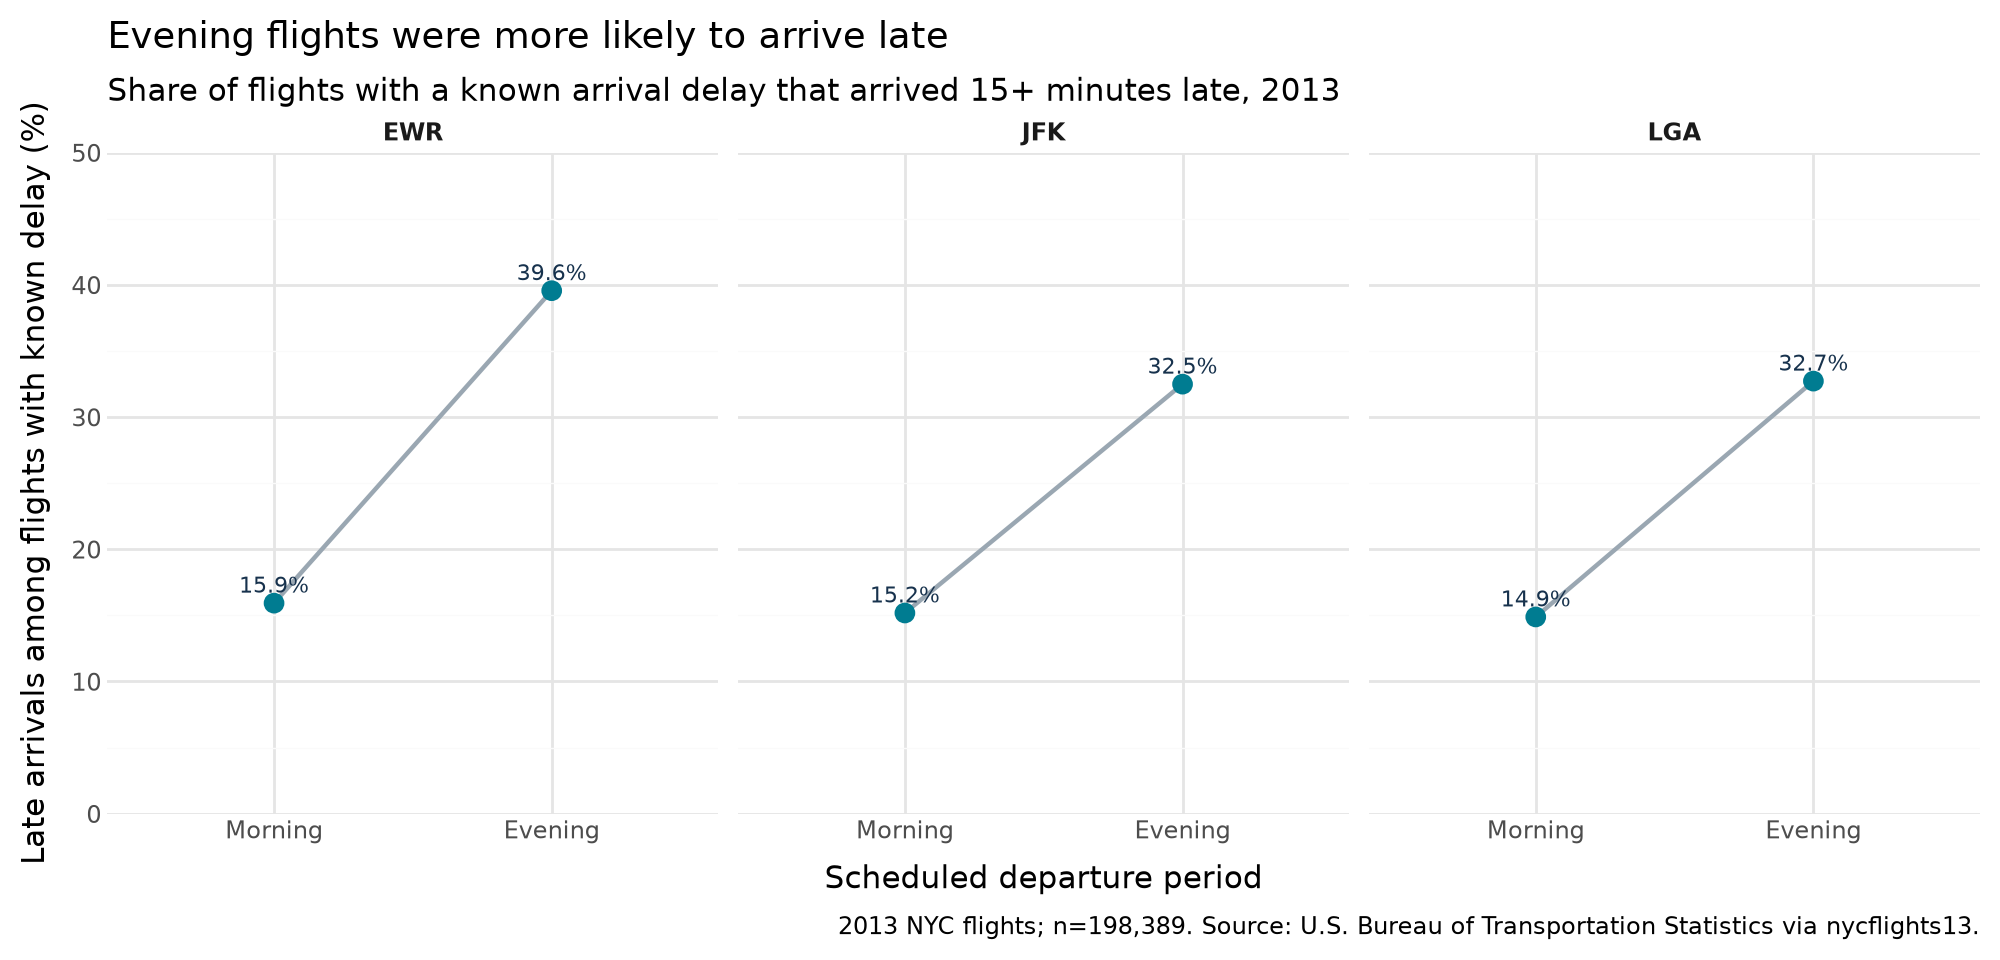

In [11]:
final_version = (
    ggplot(figure_data, aes(x="departure_period", y="late_percentage"))
    + geom_line(aes(group=1), color="#9AA7B2", size=0.9)
    + geom_point(color="#007C91", size=3.2)
    + geom_text(aes(label="rate_label"), nudge_y=1.4, size=8, color="#17324D")
    + facet_wrap("~origin", nrow=1)
    + scale_x_discrete(labels={"Morning (06-11)": "Morning", "Evening (18-23)": "Evening"})
    + scale_y_continuous(limits=(0, 50), breaks=[0, 10, 20, 30, 40, 50], expand=(0, 0))
    + plot_labels
    + plot_theme
)
final_version.save("figure.png", width=10, height=4.8, dpi=160, verbose=False)
final_version

With one connected pair of points in each airport panel, the morning-to-evening change is easier to follow and each airport's pattern is easier to distinguish across the three panels than with adjacent bars. Because the comparison focuses on change between periods, the direction and steepness of each line communicate the main finding more clearly than emphasizing each value's distance from zero.

### 4(d) Figure caption

Among flights with a recorded arrival delay in 2013, evening departures (scheduled hours 18-23) had a higher share of arrivals at least 15 minutes late than morning departures (hours 06-11) at all three New York City airports. Evening versus morning rates were 39.6% vs 15.9% at EWR, 32.5% vs 15.2% at JFK, and 32.7% vs 14.9% at LGA. The figure includes 198,389 flights with a known arrival delay in those time windows. Source: U.S. Bureau of Transportation Statistics via nycflights13. This descriptive comparison cannot show that departure time caused delays.